<a href="https://colab.research.google.com/github/rafi1624/Machine-Learning_18_Rafi-Abyantara/blob/main/JS08/JS08%20-%20Tugas%20Lab%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install hdbscan matplotlib seaborn scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, confusion_matrix

# 1. Memuat Dataset Contoh (Iris Dataset)
# Dataset ini memiliki 3 kelas asli (label asli)
iris = load_iris()
X = iris.data
y_true = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print(f"Dataset Iris dimuat dengan {X.shape[0]} sampel dan {X.shape[1]} fitur.")

Dataset Iris dimuat dengan 150 sampel dan 4 fitur.


In [ ]:
# 2. Menjalankan Clustering HDBSCAN
# Anda dapat menyesuaikan min_cluster_size dan min_samples
clusterer = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5, gen_min_span_tree=True)
labels = clusterer.fit_predict(X)

# Menghitung metrik
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("=== HASIL CLUSTERING HDBSCAN ===")
print(f"Jumlah cluster yang terbentuk: {n_clusters_}")
print(f"Banyaknya noise (titik outliers): {n_noise_} dari {len(labels)} sampel")

=== HASIL CLUSTERING HDBSCAN ===
Jumlah cluster yang terbentuk: 2
Banyaknya noise (titik outliers): 0 dari 150 sampel


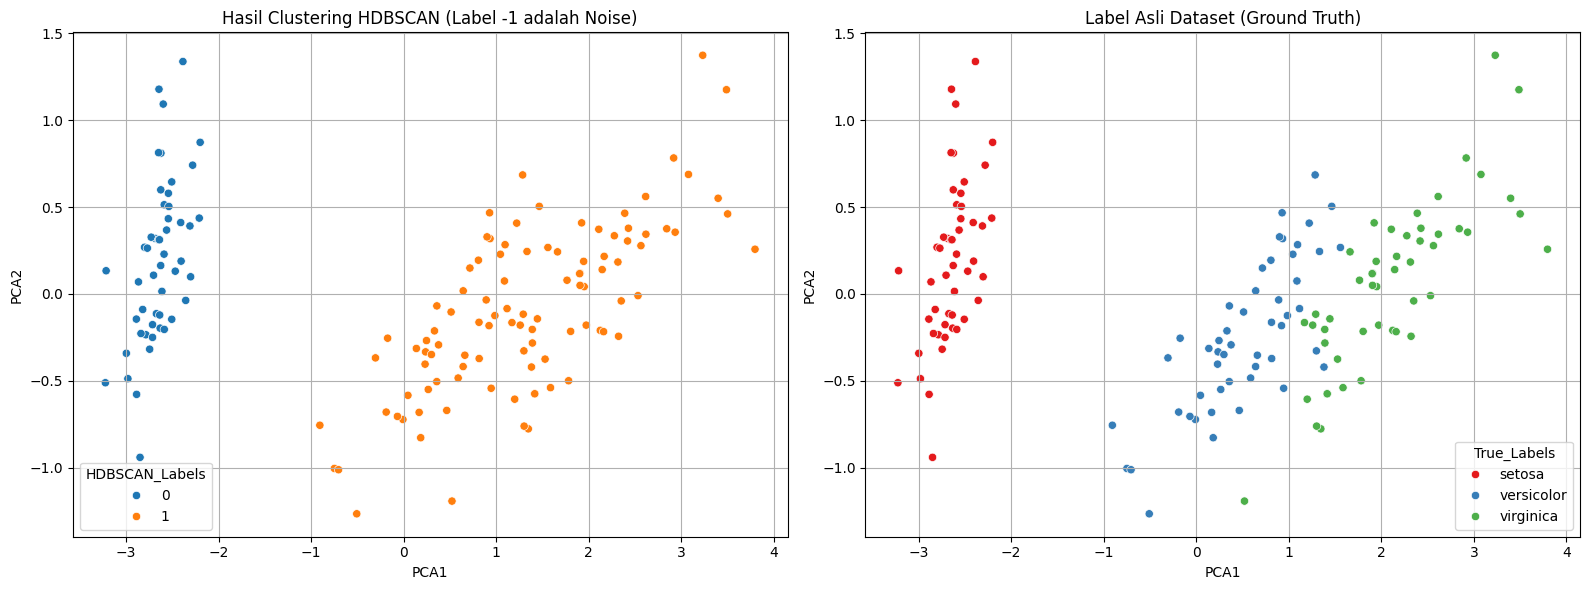

In [ ]:
# 3. Reduksi Dimensi dengan PCA untuk Visualisasi 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Membuat DataFrame untuk visualisasi
df_vis = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
df_vis['HDBSCAN_Labels'] = labels
df_vis['True_Labels'] = [target_names[i] for i in y_true]

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Hasil HDBSCAN
sns.scatterplot(
    x='PCA1', y='PCA2',
    hue='HDBSCAN_Labels',
    palette='tab10',
    data=df_vis,
    ax=axes[0],
    legend='full'
)
axes[0].set_title('Hasil Clustering HDBSCAN (Label -1 adalah Noise)')
axes[0].grid(True)

# Plot Label Asli
sns.scatterplot(
    x='PCA1', y='PCA2',
    hue='True_Labels',
    palette='Set1',
    data=df_vis,
    ax=axes[1]
)
axes[1].set_title('Label Asli Dataset (Ground Truth)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# 4. Analisis Singkat Perbandingan
ari_score = adjusted_rand_score(y_true, labels)
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print("\nCatatan Analisis:")
print("- Nilai ARI berkisar antara -1 hingga 1. Nilai mendekati 1 menunjukkan kecocokan yang sangat tinggi dengan label asli.")
print("- HDBSCAN adalah clustering berbasis kepadatan (density-based), sehingga wajar jika terdapat noise (-1) pada area transisi antar cluster.")
print("- Bandingkan visualisasi kiri dan kanan untuk melihat apakah pengelompokkan alami HDBSCAN berhasil memisahkan kelas asli.")

Adjusted Rand Index (ARI): 0.5681

Catatan Analisis:
- Nilai ARI berkisar antara -1 hingga 1. Nilai mendekati 1 menunjukkan kecocokan yang sangat tinggi dengan label asli.
- HDBSCAN adalah clustering berbasis kepadatan (density-based), sehingga wajar jika terdapat noise (-1) pada area transisi antar cluster.
- Bandingkan visualisasi kiri dan kanan untuk melihat apakah pengelompokkan alami HDBSCAN berhasil memisahkan kelas asli.
